# Similarity computation benchmarks — matchms 1.0

Reproduce the all-vs-all similarity and indexed entropy search figures from **raw timings** generated by `benchmark_matchms_similarity_computation.py`. Set `RESULTS_DIR` below, then restart the kernel and run all cells. This notebook requires the revised script's schema version 2 output; it does not import matchms or MS-Entropy.

**Interpretation.** These are native-API runtime comparisons, not identification-accuracy or score-equivalence experiments. `EntropySearch`, the linear cosine variants, and MS-Entropy can merge close peaks; BLINK discretizes m/z. MS-Entropy reference conversion is outside its index/matrix timers, while matchms public API preparation is included. The 1M and 2M reference-row cases repeat the 500k base library. A matrix contains N² output cells; indexed and symmetric algorithms need not perform N² individual pairwise computations. Times and speedups are descriptive statistics, not confidence intervals.

In [4]:
from pathlib import Path
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set to the production run directory, or override via an environment variable.
RESULTS_DIR = Path("/home/daisy/Florian/benchmarking_runs/results/scoring_matchms_1_0_0_run_01")
FIGURE_DIR = RESULTS_DIR / "figures"
ALL_VS_ALL_X = "matrix_cells"  # Alternative: "n_spectra"
SHOW_REPEAT_RANGE = False       # Optional min–max bars (not confidence intervals)

plt.rcParams.update({
    "figure.figsize": (7.2, 5.0), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

## 1. Load and validate the run

The run configuration defines the full expected grid, including intentionally omitted stages or external baselines. Raw rows must be unique, successful, complete, and have finite positive durations. This prevents a partial run, stale summary, or duplicate repeat from being silently plotted. Summary statistics are recomputed here, rather than read from the script's summary CSVs.

In [5]:
config_path = RESULTS_DIR / "benchmark_config.json"
with config_path.open(encoding="utf-8") as handle:
    config = json.load(handle)
if config.get("schema_version") != 2 or config.get("benchmark") != "matchms_1.0_scoring_paper":
    raise ValueError("Use a run from the revised scoring script (schema 2).")
if config.get("status") != "complete":
    raise ValueError(f"Run is not complete: {config.get('status')}; inspect {config_path} and raw CSVs.")
args = config["arguments"]
settings = config["scientific_settings"]
manifest = config["methods"]
base_size = settings["base_reference_size"]
n_queries = settings["n_query_spectra"]
is_smoke = bool(args["smoke"])

print(f"Run: {RESULTS_DIR.resolve()}")
print(f"matchms: {config['environment']['packages']['matchms']}; "
      f"MS-Entropy: {config['environment']['packages'].get('ms_entropy')}")
print(f"Python: {config['environment']['python'].split()[0]}")
print(f"CPU: {config['environment']['processor']}; logical CPUs: "
      f"{config['environment']['logical_cpu_count']}")
print(f"Dataset SHA256: {config['dataset'].get('sha256')}")
print(f"Script SHA256: {config['benchmark_script']['sha256']}")
print(f"Tolerance: {settings['mz_tolerance_da']} Da; entropy dtype: {settings['entropy_dtype']}")
print(f"Matrix input policy: {args['matrix_input']}")
if is_smoke:
    print("SMOKE TEST ONLY — do not use these timings as publication results.")
display(pd.Series(config["dataset"].get("selected", {}), name="Selected library"))

Run: /home/daisy/Florian/benchmarking_runs/results/scoring_matchms_1_0_0_run_01
matchms: 1.0.0; MS-Entropy: 1.5.3
Python: 3.13.16
CPU: 13th Gen Intel(R) Core(TM) i9-13900K; logical CPUs: 32
Dataset SHA256: 9dd27267899dabb38c0e53481386e0c9a50a2e51c3fc54fbc297caccebc10e33
Script SHA256: d63a9d0c0765a39934950814d192cff192e8ee424845e42954d2c1c3abb85f97
Tolerance: 0.01 Da; entropy dtype: float32
Matrix input policy: native


n_spectra       5.000000e+05
n_peaks         1.692684e+07
min_peaks       2.000000e+00
median_peaks    2.000000e+01
mean_peaks      3.385369e+01
max_peaks       7.330000e+02
Name: Selected library, dtype: float64

In [6]:
# Verify the saved selection is consistent with the declared experiment.
with np.load(RESULTS_DIR / "sample_selection.npz", allow_pickle=False) as selection:
    reference_indices = selection["reference_indices"]
    query_positions = selection["query_positions"]
    query_source_indices = selection["query_source_indices"]
expected_n = max(settings["all_vs_all_sizes"]) if args["skip_query"] else base_size
assert reference_indices.shape == (expected_n,)
assert len(np.unique(reference_indices)) == expected_n
assert reference_indices.min() >= 0 and reference_indices.max() < config["dataset"]["n_loaded_spectra"]
if args["skip_query"]:
    assert query_positions.size == 0 and query_source_indices.size == 0
else:
    assert query_positions.shape == (n_queries,)
    assert len(np.unique(query_positions)) == n_queries
    assert query_positions.min() >= 0 and query_positions.max() < expected_n
    np.testing.assert_array_equal(reference_indices[query_positions], query_source_indices)
    display(pd.DataFrame({"query_position": query_positions, "source_row": query_source_indices}))

,query_position,source_row
0,42586,499029
1,61340,28880
2,65213,326142
3,78623,86088
4,125923,127543
5,149319,9937
6,205422,112764
7,287486,227309
8,369521,48135
9,438110,95855


In [7]:
def expected_rows(stage):
    rows = []
    if stage == "all_vs_all":
        for method in manifest["all_vs_all"]:
            for n in settings["all_vs_all_sizes"]:
                for repeat in range(args["all_vs_all_repeats"]):
                    jobs = method["n_jobs"]
                    rows.append(dict(benchmark="all_vs_all", family=method["family"],
                        method=method["method"], n_spectra=n, matrix_cells=n*n, n_jobs=jobs,
                        execution="serial" if jobs == 1 else "parallel", repeat=repeat,
                        score_fields="score", representation_preparation_included=
                            method["representation_preparation_included"], input_representation=method["input_representation"]))
    else:
        is_index = stage == "query_index"
        repeats = args["query_index_repeats" if is_index else "query_search_repeats"]
        for method in manifest["indexed"]:
            for n in settings["query_reference_sizes"]:
                for repeat in range(repeats):
                    row = dict(method=method["method"], n_reference=n, n_jobs=1,
                               execution="serial", duplication_factor=max(1, n//base_size),
                               repeat=repeat)
                    if is_index:
                        row.update(benchmark="query_index_build", library_preparation_included=
                                   method["library_preparation_included"])
                    else:
                        row.update(benchmark="query_search", n_queries=n_queries,
                                   query_preparation_included=True, index_build_included=False)
                    rows.append(row)
    return pd.DataFrame(rows)


def validated_raw(stage):
    expected = expected_rows(stage)
    if expected.empty:
        print(f"{stage}: intentionally omitted")
        return None
    raw = pd.read_csv(RESULTS_DIR / f"{stage}_timings.csv")
    required = set(expected.columns) | {"status", "seconds"}
    if stage == "query_search":
        required.add("seconds_per_query")
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"{stage}: missing columns {sorted(missing)}")
    bad = raw.loc[~raw.status.eq("ok") | ~np.isfinite(raw.seconds) | ~raw.seconds.gt(0)]
    if not bad.empty:
        display(bad)
        raise ValueError(f"{stage}: failed or invalid timing rows")
    keys = ["method", "n_jobs", "repeat", "n_spectra" if stage == "all_vs_all" else "n_reference"]
    if raw.duplicated(keys).any() or expected.duplicated(keys).any():
        raise ValueError(f"{stage}: duplicate repeat keys")
    comparison = expected.merge(raw[expected.columns], on=list(expected.columns),
                                how="outer", indicator=True, validate="one_to_one")
    if not comparison["_merge"].eq("both").all():
        display(comparison.loc[comparison["_merge"].ne("both")].head(30))
        raise ValueError(f"{stage}: missing, unexpected or inconsistent rows")
    if stage == "query_search":
        np.testing.assert_allclose(raw.seconds_per_query, raw.seconds / raw.n_queries,
                                   rtol=1e-10, atol=1e-12)
    print(f"{stage}: {len(raw):,} validated timing rows")
    return raw


GROUPS = {
    "all_vs_all": ["family", "method", "n_spectra", "n_jobs", "execution",
                   "representation_preparation_included", "input_representation"],
    "query_index": ["method", "n_reference", "n_jobs", "execution", "duplication_factor",
                    "library_preparation_included"],
    "query_search": ["method", "n_reference", "n_queries", "n_jobs", "execution",
                     "duplication_factor", "query_preparation_included", "index_build_included"],
}

def summarize(raw, stage):
    if raw is None:
        return None
    return raw.groupby(GROUPS[stage], dropna=False)["seconds"].agg(
        n_repeats="count", seconds_median="median", seconds_mean="mean",
        seconds_std="std", seconds_min="min", seconds_max="max").reset_index()

all_vs_all_raw = validated_raw("all_vs_all")
query_index_raw = validated_raw("query_index")
query_search_raw = validated_raw("query_search")
all_vs_all = summarize(all_vs_all_raw, "all_vs_all")
query_index = summarize(query_index_raw, "query_index")
query_search = summarize(query_search_raw, "query_search")

if not args["skip_msentropy"]:
    representation_preparation = pd.read_csv(RESULTS_DIR / "representation_preparation.csv")
    if len(representation_preparation) != 1:
        raise ValueError("Expected one MS-Entropy reference preparation record.")
    prep = representation_preparation.iloc[0]
    expected_prep = max(settings["all_vs_all_sizes"]) if args["skip_query"] else min(base_size, max(settings["query_reference_sizes"]))
    if not args["skip_all_vs_all"]:
        expected_prep = max(expected_prep, max(settings["all_vs_all_sizes"]))
    if (prep.n_spectra != expected_prep or not np.isfinite(prep.seconds) or prep.seconds <= 0
            or not 0 < prep.output_peaks <= prep.input_peaks):
        raise ValueError("Invalid MS-Entropy preparation statistics.")
    display(representation_preparation.T)
else:
    representation_preparation = None

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

all_vs_all: 324 validated timing rows
query_index: 99 validated timing rows
query_search: 165 validated timing rows


,0
representation,msentropy_precleaned
n_spectra,500000
input_peaks,16926845
output_peaks,14400694
mean_input_peaks,33.85369
mean_output_peaks,28.801388
seconds,5.555644
precursor_ions_removal_da,NaN
noise_threshold,0.0
min_ms2_difference_in_da,0.021


## 2. Shared plotting settings

Greedy and Hungarian baselines are run with **matchms 1.x**, not older package releases. By default the specialized non-indexed methods receive lists of the same collection-derived spectra, created outside timers; indexed methods receive collections. `--matrix-input collection` restores the original all-collection design. We distinguish the general entropy scorer from its separated-peak variant and mark the MS-Entropy low-level CPU core with an asterisk: its reference conversion is excluded from matrix/index timings. All plot labels use reference *rows*, not unique compounds or spectra. Repeated-reference points use square markers.

In [8]:
METHOD_LABELS = {
    "cosine_hungarian": "CosineHungarian",
    "cosine_greedy": "CosineGreedy",
    "cosine_linear": "CosineLinear",
    "cosine_blink": "CosineBlink",
    "cosine": "Cosine (Flash)",
    "modified_cosine_hungarian": "ModifiedCosineHungarian",
    "modified_cosine_greedy": "ModifiedCosineGreedy",
    "modified_cosine_linear": "ModifiedCosineLinear",
    "modified_cosine": "ModifiedCosine (Flash)",
    "entropy_fragment": "Entropy (fragment)",
    "entropy_hybrid": "Entropy (hybrid)",
    "entropy_search": "EntropySearch",
    "matchms_entropy_fragment": "Entropy (fragment)",
    "matchms_entropy_search_fragment": "EntropySearch",
    "msentropy_core_fragment_cpu": "MS-Entropy (CPU core)*",
}
METHOD_COLORS = {
    "cosine_hungarian": "black", "cosine_greedy": "dodgerblue",
    "cosine_linear": "teal", "cosine_blink": "darkorange", "cosine": "crimson",
    "modified_cosine_hungarian": "black", "modified_cosine_greedy": "dodgerblue",
    "modified_cosine_linear": "teal", "modified_cosine": "crimson",
    "entropy_fragment": "crimson", "entropy_hybrid": "teal", "entropy_search": "purple",
    "matchms_entropy_fragment": "crimson", "matchms_entropy_search_fragment": "purple",
    "msentropy_core_fragment_cpu": "dimgray",
}
FAMILIES = {
    "cosine": ["cosine_hungarian", "cosine_greedy", "cosine_linear", "cosine_blink", "cosine"],
    "modified_cosine": ["modified_cosine_hungarian", "modified_cosine_greedy",
                        "modified_cosine_linear", "modified_cosine"],
    "entropy": ["entropy_fragment", "entropy_hybrid", "entropy_search", "msentropy_core_fragment_cpu"],
}
QUERY_ORDER = ["matchms_entropy_fragment", "matchms_entropy_search_fragment", "msentropy_core_fragment_cpu"]
X_LABEL = {"matrix_cells": "Dense score-matrix entries (N²)", "n_spectra": "Number of spectra"}[ALL_VS_ALL_X]


def save_figure(fig, name):
    if is_smoke:
        fig.suptitle("SMOKE TEST — NOT FOR PUBLICATION", fontsize=12)
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(FIGURE_DIR / f"{name}.{suffix}", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def curve(ax, part, method, *, x, y="seconds_median", label=None, linestyle="--", scale=1.0):
    if part.empty:
        return
    part = part.sort_values(x)
    values = part[x].to_numpy()
    times = part[y].to_numpy() * scale
    color = METHOD_COLORS[method]
    ax.plot(values, times, linestyle=linestyle, marker="o", markersize=5,
            linewidth=1.7, color=color, label=label or METHOD_LABELS[method])
    if "duplication_factor" in part:
        repeated = part.duplication_factor.to_numpy() > 1
        ax.plot(values[repeated], times[repeated], linestyle="none", marker="s",
                markersize=6, color=color)
    if SHOW_REPEAT_RANGE and y == "seconds_median":
        low = (part[y] - part.seconds_min).to_numpy() * scale
        high = (part.seconds_max - part[y]).to_numpy() * scale
        ax.errorbar(values, times, yerr=np.maximum(0, np.vstack([low, high])),
                    fmt="none", color=color, capsize=2, alpha=0.6)


def format_axes(ax, *, xlabel, ylabel="Wall-clock time (s)", title="", log_y=True, legend=True):
    ax.set_xscale("log")
    if log_y:
        ax.set_yscale("log")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(True, which="both", alpha=0.2)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)


def matrix_panel(ax, family, title):
    data = all_vs_all.loc[all_vs_all.family.eq(family) & all_vs_all.n_jobs.eq(1)].copy()
    data["matrix_cells"] = data.n_spectra ** 2
    for method in FAMILIES[family]:
        curve(ax, data.loc[data.method.eq(method)], method, x=ALL_VS_ALL_X)
    format_axes(ax, xlabel=X_LABEL, title=title)


def query_panel(ax, data, title, *, per_query=False):
    for method in QUERY_ORDER:
        curve(ax, data.loc[data.method.eq(method)], method, x="n_reference",
              scale=1000/n_queries if per_query else 1.0)
    ylabel = (f"Batch time / {n_queries} (ms)" if per_query else
              f"Wall-clock time for {n_queries} queries (s)" if "n_queries" in data else
              "Index-build wall-clock time (s)")
    format_axes(ax, xlabel="Number of reference rows", ylabel=ylabel, title=title)

## 3. Manuscript figure

The original four panels are retained. If one experiment was intentionally skipped, the corresponding standalone panels are generated instead; the combined manuscript figure requires both stages. The abscissa in panels A–C is the number of **output entries**, not the number of actual score calculations. Panel D includes raw query preparation; the library index is already built.

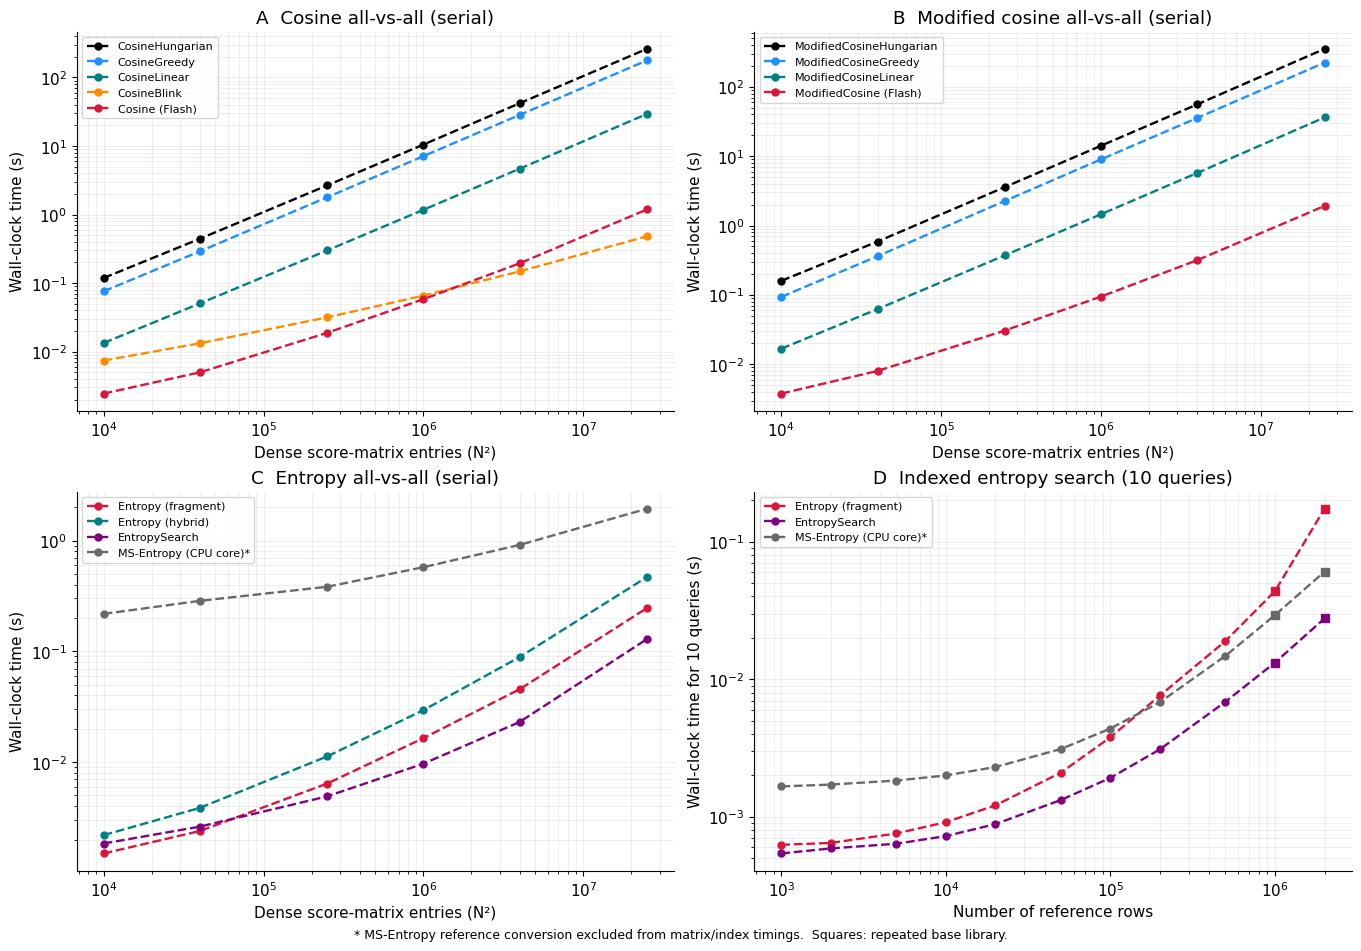

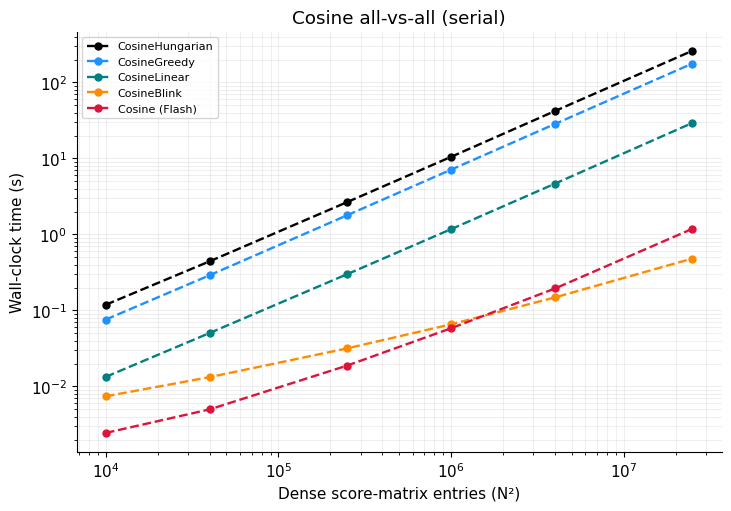

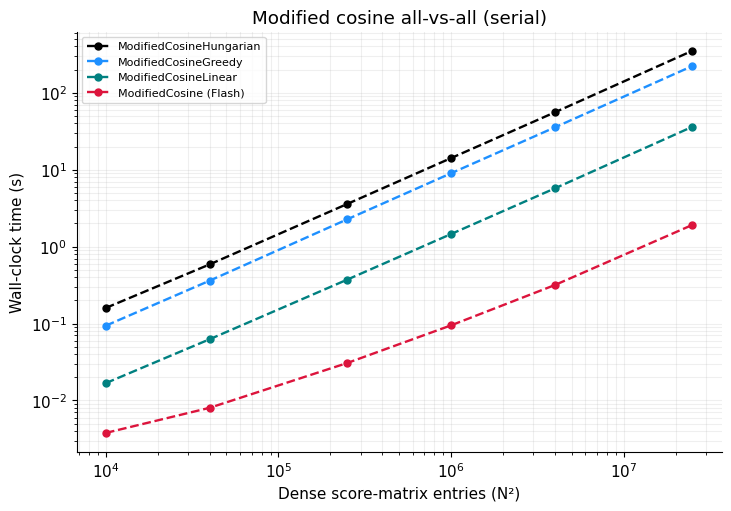

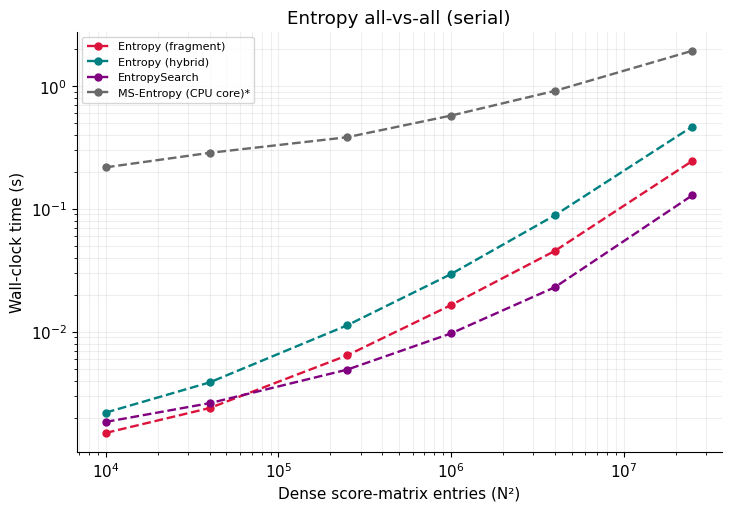

In [9]:
if all_vs_all is not None and query_search is not None:
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.4), layout="constrained")
    matrix_panel(axes[0, 0], "cosine", "A  Cosine all-vs-all (serial)")
    matrix_panel(axes[0, 1], "modified_cosine", "B  Modified cosine all-vs-all (serial)")
    matrix_panel(axes[1, 0], "entropy", "C  Entropy all-vs-all (serial)")
    query_panel(axes[1, 1], query_search, f"D  Indexed entropy search ({n_queries} queries)")
    # A separate caption line keeps the benchmark caveats with the exported figure.
    notes = []
    if not args["skip_msentropy"]:
        notes.append("* MS-Entropy reference conversion excluded from matrix/index timings.")
    if query_search.duplication_factor.gt(1).any():
        notes.append("Squares: repeated base library.")
    if notes:
        fig.supxlabel("  ".join(notes), fontsize=9)
    save_figure(fig, "matchms_v1_similarity_computation_benchmarking")
else:
    print("Combined figure requires both benchmark stages; standalone figures below.")

if all_vs_all is not None:
    for family, title in [("cosine", "Cosine all-vs-all"),
                          ("modified_cosine", "Modified cosine all-vs-all"),
                          ("entropy", "Entropy all-vs-all")]:
        fig, ax = plt.subplots(layout="constrained")
        matrix_panel(ax, family, title + " (serial)")
        save_figure(fig, f"all_vs_all_{family}")

## 4. Multicore scaling

For the five implementations that accept `n_jobs`, compare matched configurations using median(serial) / median(parallel). `n_jobs=-1` requests the library's own automatic worker policy; it is not a guarantee that all logical CPUs execute simultaneously. No cross-version speedups are inferred.

,method,n_spectra,n_jobs,speedup
0,cosine,100,-1,0.453967
1,cosine,200,-1,0.941240
2,cosine,500,-1,2.382087
3,cosine,1000,-1,5.460530
4,cosine,2000,-1,10.583211
5,cosine,5000,-1,13.084774
6,entropy_fragment,100,-1,0.322251
7,entropy_fragment,200,-1,0.458119
8,entropy_fragment,500,-1,0.838059
9,entropy_fragment,1000,-1,1.745582


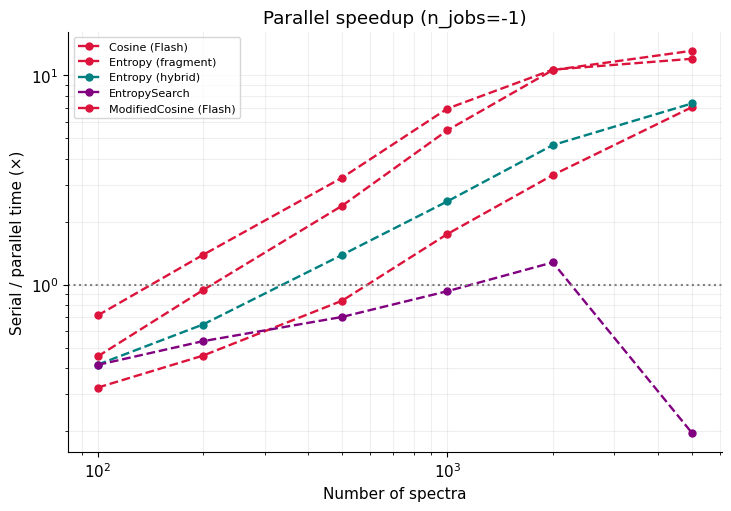

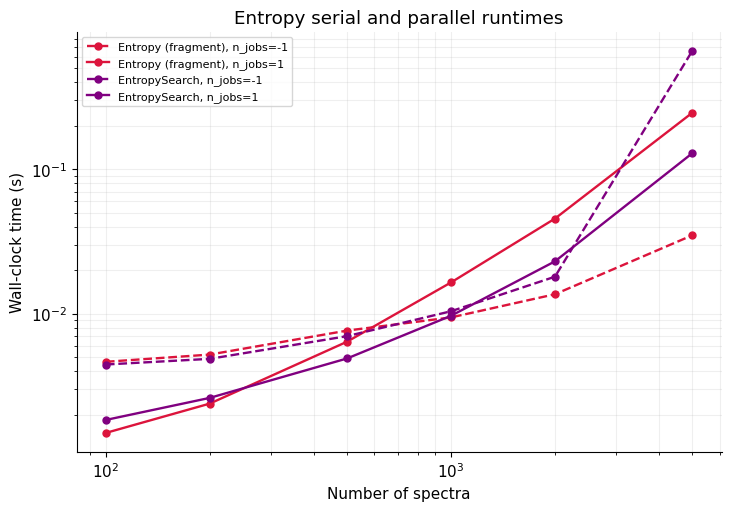

In [10]:
if all_vs_all is not None:
    parallel = all_vs_all.loc[all_vs_all.n_jobs.ne(1)].copy()
    if not parallel.empty:
        serial = all_vs_all.loc[all_vs_all.n_jobs.eq(1), ["method", "n_spectra", "seconds_median"]]
        parallel_speedup = parallel.merge(serial.rename(columns={"seconds_median": "serial_seconds"}),
                                           on=["method", "n_spectra"], validate="many_to_one")
        parallel_speedup["speedup"] = parallel_speedup.serial_seconds / parallel_speedup.seconds_median
        display(parallel_speedup[["method", "n_spectra", "n_jobs", "speedup"]])
        parallel_speedup.to_csv(FIGURE_DIR / "parallel_speedups.csv", index=False)
        fig, ax = plt.subplots(layout="constrained")
        for method, part in parallel_speedup.groupby("method"):
            curve(ax, part, method, x="n_spectra", y="speedup")
        ax.axhline(1, color="gray", linestyle=":")
        format_axes(ax, xlabel="Number of spectra", ylabel="Serial / parallel time (×)",
                    title=f"Parallel speedup (n_jobs={args['parallel_jobs']})")
        save_figure(fig, "parallel_speedups")

        fig, ax = plt.subplots(layout="constrained")
        for method in ["entropy_fragment", "entropy_search"]:
            subset = all_vs_all.loc[all_vs_all.method.eq(method)]
            for jobs, part in subset.groupby("n_jobs"):
                curve(ax, part, method, x="n_spectra", linestyle="-" if jobs == 1 else "--",
                      label=f"{METHOD_LABELS[method]}, n_jobs={jobs}")
        format_axes(ax, xlabel="Number of spectra", title="Entropy serial and parallel runtimes")
        save_figure(fig, "entropy_parallel_runtimes")
    else:
        print("Parallel runs intentionally omitted.")

## 5. Indexed entropy search and index construction

Query time includes preparation and dense scoring; index construction is excluded. Dividing the ten-query batch duration by ten gives **average time per query within that batch**, not a measured median individual-query latency. For the low-level MS-Entropy CPU core, the separately measured reference conversion is excluded from index construction; the index may also include structures not used by open search. This is a native API comparison, not an equal-kernel benchmark.

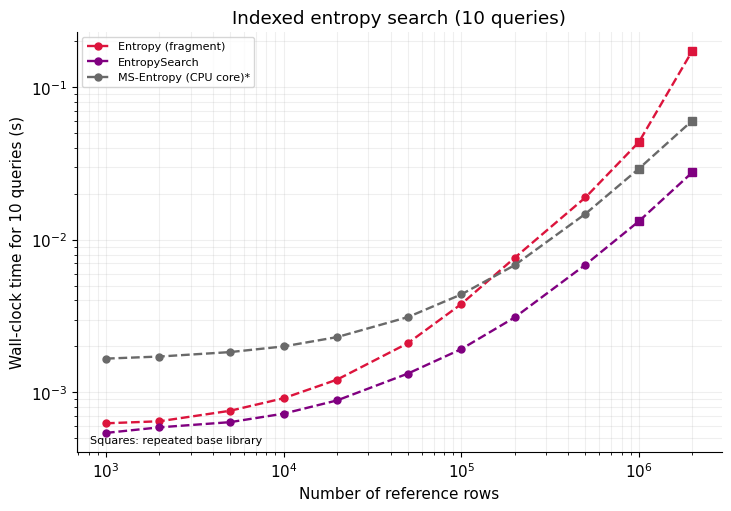

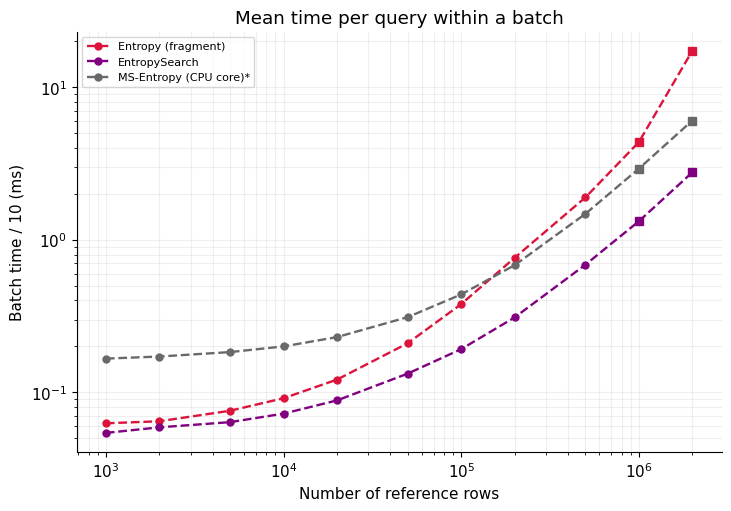

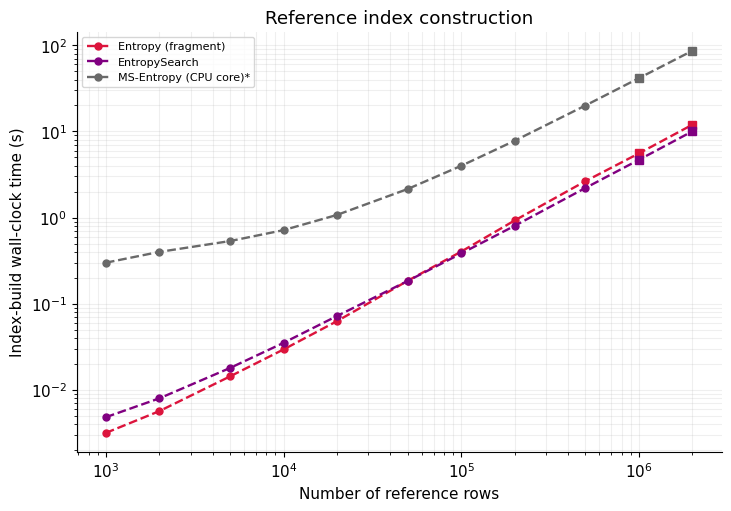

In [11]:
if query_search is not None:
    fig, ax = plt.subplots(layout="constrained")
    query_panel(ax, query_search, f"Indexed entropy search ({n_queries} queries)")
    if query_search.duplication_factor.gt(1).any():
        ax.text(0.02, 0.02, "Squares: repeated base library", transform=ax.transAxes, fontsize=8)
    save_figure(fig, "query_search_time")

    fig, ax = plt.subplots(layout="constrained")
    query_panel(ax, query_search, "Mean time per query within a batch", per_query=True)
    save_figure(fig, "query_time_per_spectrum")

    fig, ax = plt.subplots(layout="constrained")
    query_panel(ax, query_index, "Reference index construction")
    save_figure(fig, "query_index_build_time")

,method,n_reference,speedup_vs_entropy
0,matchms_entropy_fragment,1000,1.000000
1,matchms_entropy_fragment,2000,1.000000
2,matchms_entropy_fragment,5000,1.000000
3,matchms_entropy_fragment,10000,1.000000
4,matchms_entropy_fragment,20000,1.000000
5,matchms_entropy_fragment,50000,1.000000
6,matchms_entropy_fragment,100000,1.000000
7,matchms_entropy_fragment,200000,1.000000
8,matchms_entropy_fragment,500000,1.000000
9,matchms_entropy_fragment,1000000,1.000000


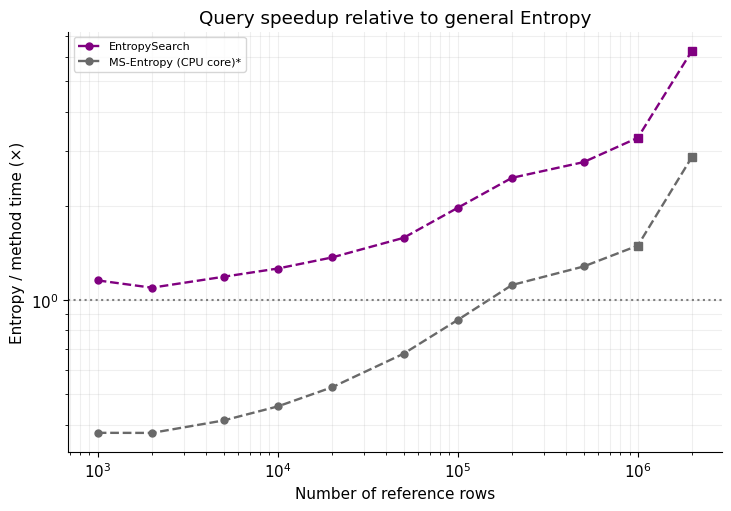

method,matchms_entropy_fragment,matchms_entropy_search_fragment,msentropy_core_fragment_cpu,entropy_search_over_msentropy
n_reference,,,,
1000,0.000627,0.000542,0.001663,0.325868
2000,0.000646,0.000590,0.001716,0.343582
5000,0.000757,0.000638,0.001835,0.347444
10000,0.000915,0.000725,0.001999,0.362584
20000,0.001212,0.000885,0.002301,0.384726
50000,0.002097,0.001326,0.003110,0.426393
100000,0.003786,0.001920,0.004380,0.438244
200000,0.007616,0.003098,0.006815,0.454490
500000,0.018924,0.006857,0.014776,0.464043


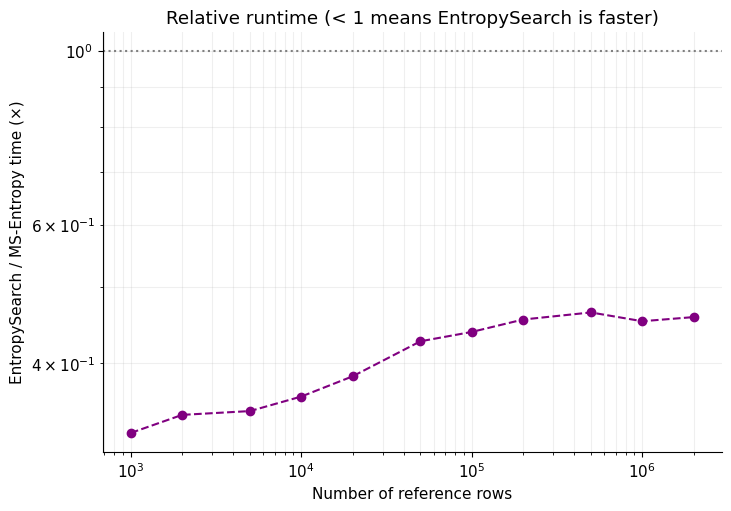

In [12]:
if query_search is not None:
    baseline = query_search.loc[query_search.method.eq("matchms_entropy_fragment"),
                                ["n_reference", "seconds_median"]].rename(
                                    columns={"seconds_median": "baseline_seconds"})
    relative_query = query_search.merge(baseline, on="n_reference", validate="many_to_one")
    relative_query["speedup_vs_entropy"] = relative_query.baseline_seconds / relative_query.seconds_median
    relative_query.to_csv(FIGURE_DIR / "query_speedups.csv", index=False)
    display(relative_query[["method", "n_reference", "speedup_vs_entropy"]])
    fig, ax = plt.subplots(layout="constrained")
    for method in QUERY_ORDER[1:]:
        curve(ax, relative_query.loc[relative_query.method.eq(method)], method,
              x="n_reference", y="speedup_vs_entropy")
    ax.axhline(1, color="gray", linestyle=":")
    format_axes(ax, xlabel="Number of reference rows", ylabel="Entropy / method time (×)",
                title="Query speedup relative to general Entropy")
    save_figure(fig, "query_speedups")

    if not args["skip_msentropy"]:
        comparison = query_search.pivot(index="n_reference", columns="method", values="seconds_median")
        comparison["entropy_search_over_msentropy"] = (comparison["matchms_entropy_search_fragment"] /
                                                       comparison["msentropy_core_fragment_cpu"])
        comparison.to_csv(FIGURE_DIR / "entropy_search_vs_msentropy.csv")
        display(comparison)
        fig, ax = plt.subplots(layout="constrained")
        ax.plot(comparison.index, comparison.entropy_search_over_msentropy, "o--", color="purple")
        ax.axhline(1, color="gray", linestyle=":")
        format_axes(ax, xlabel="Number of reference rows", ylabel="EntropySearch / MS-Entropy time (×)",
                    title="Relative runtime (< 1 means EntropySearch is faster)", legend=False)
        save_figure(fig, "entropy_search_vs_msentropy")

## 6. Scaling diagnostics

Dense-output throughput counts the number of returned matrix cells per second; it is not the number of independent pair calculations performed by an implementation. A local scaling exponent is a finite difference between adjacent measured points on log–log axes; it is not an asymptotic complexity estimate. Replicated-library intervals may have different behavior from real-library intervals.

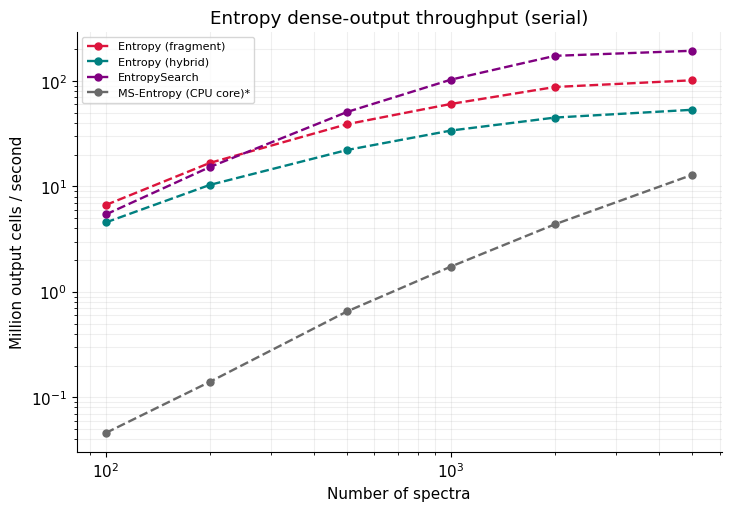

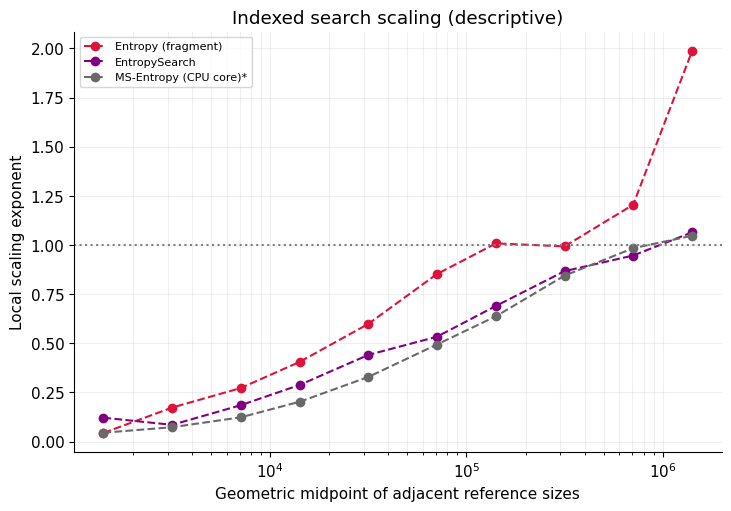

In [13]:
if all_vs_all is not None:
    throughput = all_vs_all.copy()
    throughput["million_output_cells_per_second"] = throughput.n_spectra**2 / throughput.seconds_median / 1e6
    fig, ax = plt.subplots(layout="constrained")
    for method in FAMILIES["entropy"]:
        part = throughput.loc[throughput.method.eq(method) & throughput.n_jobs.eq(1)]
        curve(ax, part, method, x="n_spectra", y="million_output_cells_per_second")
    format_axes(ax, xlabel="Number of spectra", ylabel="Million output cells / second",
                title="Entropy dense-output throughput (serial)")
    save_figure(fig, "entropy_matrix_throughput")

if query_search is not None and query_search.n_reference.nunique() > 1:
    fig, ax = plt.subplots(layout="constrained")
    for method in QUERY_ORDER:
        part = query_search.loc[query_search.method.eq(method)].sort_values("n_reference")
        if len(part) < 2:
            continue
        x = part.n_reference.to_numpy(dtype=float)
        y = part.seconds_median.to_numpy(dtype=float)
        ax.plot(np.sqrt(x[:-1]*x[1:]), np.diff(np.log(y))/np.diff(np.log(x)),
                "o--", color=METHOD_COLORS[method], label=METHOD_LABELS[method])
    ax.axhline(1, color="gray", linestyle=":")
    format_axes(ax, xlabel="Geometric midpoint of adjacent reference sizes", ylabel="Local scaling exponent",
                title="Indexed search scaling (descriptive)", log_y=False)
    save_figure(fig, "query_local_scaling")

## 7. Tables and timing variability

Report medians and the observed min–max ranges; standard deviations are undefined with one repeat (e.g. smoke tests). Save the raw files, provenance, and notebook alongside the figures.

In [14]:
for stage, summary in [("all_vs_all", all_vs_all), ("query_index", query_index),
                       ("query_search", query_search)]:
    if summary is None:
        continue
    report = summary.copy()
    report["relative_range"] = (report.seconds_max - report.seconds_min) / report.seconds_median
    if stage == "query_search":
        report["ms_per_query_in_batch"] = 1000 * report.seconds_median / report.n_queries
    report.to_csv(FIGURE_DIR / f"{stage}_analysis.csv", index=False)
    size_col = "n_spectra" if stage == "all_vs_all" else "n_reference"
    print(f"{stage}: largest requested size")
    display(report.loc[report[size_col].eq(report[size_col].max())].sort_values("seconds_median"))

if all_vs_all is not None:
    display(all_vs_all.loc[all_vs_all.n_jobs.eq(1)].pivot(
        index="method", columns="n_spectra", values="seconds_median"))
if query_search is not None:
    display(query_search.pivot(index="method", columns="n_reference", values="seconds_median"))
print(f"Figures and analysis tables: {FIGURE_DIR.resolve()}")

all_vs_all: largest requested size


,family,method,n_spectra,n_jobs,execution,representation_preparation_included,input_representation,n_repeats,seconds_median,seconds_mean,seconds_std,seconds_min,seconds_max,relative_range
46,entropy,entropy_fragment,5000,-1,parallel,True,spectra_collection,3,0.034886,0.034591,0.001456,0.033010,0.035878,0.082207
58,entropy,entropy_hybrid,5000,-1,parallel,True,spectra_collection,3,0.063810,0.063986,0.000358,0.063750,0.064398,0.010153
10,cosine,cosine,5000,-1,parallel,True,spectra_collection,3,0.090577,0.089670,0.002501,0.086842,0.091590,0.052421
71,entropy,entropy_search,5000,1,serial,True,spectra_collection,3,0.128925,0.129136,0.000368,0.128921,0.129560,0.004957
88,modified_cosine,modified_cosine,5000,-1,parallel,True,spectra_collection,3,0.159773,0.154823,0.008944,0.144498,0.160197,0.098256
47,entropy,entropy_fragment,5000,1,serial,True,spectra_collection,3,0.245562,0.245448,0.001101,0.244294,0.246487,0.008934
59,entropy,entropy_hybrid,5000,1,serial,True,spectra_collection,3,0.467860,0.467851,0.001116,0.466730,0.468961,0.004770
17,cosine,cosine_blink,5000,1,serial,True,list_spectrum,3,0.481632,0.482268,0.001301,0.481408,0.483765,0.004894
70,entropy,entropy_search,5000,-1,parallel,True,spectra_collection,3,0.658394,0.651213,0.037616,0.610525,0.684721,0.112693
11,cosine,cosine,5000,1,serial,True,spectra_collection,3,1.185176,1.186622,0.007365,1.180088,1.194603,0.012247


query_index: largest requested size


,method,n_reference,n_jobs,execution,duplication_factor,library_preparation_included,n_repeats,seconds_median,seconds_mean,seconds_std,seconds_min,seconds_max,relative_range
21,matchms_entropy_search_fragment,2000000,1,serial,4,True,3,10.025200,10.018998,0.047511,9.968690,10.063103,0.009418
10,matchms_entropy_fragment,2000000,1,serial,4,True,3,11.964260,12.369645,0.728333,11.934203,13.210472,0.106673
32,msentropy_core_fragment_cpu,2000000,1,serial,4,False,3,86.323722,86.325440,0.051723,86.274596,86.378000,0.001198


query_search: largest requested size


,method,n_reference,n_queries,n_jobs,execution,duplication_factor,query_preparation_included,index_build_included,n_repeats,seconds_median,seconds_mean,seconds_std,seconds_min,seconds_max,relative_range,ms_per_query_in_batch
21,matchms_entropy_search_fragment,2000000,10,1,serial,4,True,False,5,0.027649,0.027968,0.000696,0.027358,0.028856,0.054213,2.764903
32,msentropy_core_fragment_cpu,2000000,10,1,serial,4,True,False,5,0.060402,0.069071,0.019043,0.060203,0.103128,0.710665,6.040174
10,matchms_entropy_fragment,2000000,10,1,serial,4,True,False,5,0.173117,0.173220,0.000606,0.172447,0.174036,0.009178,17.311682


n_spectra,100,200,500,1000,2000,5000
method,,,,,,
cosine,0.002442,0.004987,0.018789,0.058189,0.194215,1.185176
cosine_blink,0.007410,0.013246,0.031626,0.065614,0.148249,0.481632
cosine_greedy,0.075789,0.290737,1.786359,7.109241,28.411888,177.236050
cosine_hungarian,0.118758,0.443231,2.660611,10.488595,42.027619,261.018088
cosine_linear,0.013358,0.050513,0.299532,1.172293,4.657688,29.312661
entropy_fragment,0.001499,0.002391,0.006409,0.016464,0.045499,0.245562
entropy_hybrid,0.002194,0.003867,0.011263,0.029447,0.088761,0.467860
entropy_search,0.001843,0.002619,0.004907,0.009682,0.023032,0.128925
modified_cosine,0.003786,0.008037,0.030658,0.094728,0.317147,1.914342


n_reference,1000,2000,5000,10000,20000,50000,100000,200000,500000,1000000,2000000
method,,,,,,,,,,,
matchms_entropy_fragment,0.000627,0.000646,0.000757,0.000915,0.001212,0.002097,0.003786,0.007616,0.018924,0.043629,0.173117
matchms_entropy_search_fragment,0.000542,0.000590,0.000638,0.000725,0.000885,0.001326,0.001920,0.003098,0.006857,0.013216,0.027649
msentropy_core_fragment_cpu,0.001663,0.001716,0.001835,0.001999,0.002301,0.003110,0.004380,0.006815,0.014776,0.029224,0.060402


Figures and analysis tables: /home/daisy/Florian/benchmarking_runs/results/scoring_matchms_1_0_0_run_01/figures
